# First frame, camera coordinates: tag 1, ring 30 and tags 11/12 vs CAD

No rigid body. Tags 1-5, 11 and 12 are posed independently in one frame straight from the
cached corner detections (IPPE on the undistorted corners), all in camera
coordinates. The hardcoded CAD offsets and orientations, which live in tag 1's
frame, are moved into the camera with tag 1's measured pose:

    t_pred = t_1 + R_1 @ cad_offset        R_pred = R_1 @ R_cad

so position and orientation are compared with nothing fitted or aligned.

In [1]:
# Imports
from pathlib import Path
import pickle

import cv2
import numpy as np
import matplotlib.pyplot as plt
import polars as pl
from scipy.spatial.transform import Rotation
import toml

In [2]:
# Settings
try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:  # running cell-by-cell in an interactive kernel
    NOTEBOOK_DIR = Path.cwd()
    if NOTEBOOK_DIR.name != "jitter_model":
        NOTEBOOK_DIR = NOTEBOOK_DIR / "jitter_model"
PROJECT_ROOT = NOTEBOOK_DIR.parent
RECORDING_DIR = PROJECT_ROOT / "data" / "dome" / "sep18_26" / "dome_rb_def"
DETECTION_CACHE = RECORDING_DIR / "jitter_detections.pkl"
CALIBRATION_TOML = (
    PROJECT_ROOT
    / "data"
    / "calibration"
    / "dual_160"
    / "calib_radxa_sep18_26"
    / "stereo_calibration.toml"
)

CAMERA = "cam0"
FRAME = 0
TAG_SIZE_M = 0.05
REFERENCE_ID = 1
EULER_ORDER = "xyz"
MM = 1000.0

# CAD, in tag 1's frame: tag centre offset (x, y, z) in mm, and orientation as
# xyz Euler angles in degrees.
# Ring 30 (2-5) sits 56.61 mm out and 15.17 mm down; each tag is tag 1 tilted 30
# degrees about the axis at right angles to its azimuth, with no in-plane roll.
# Tag 12 is on ring 60 at 180 degrees (98.058 mm out, 56.61 down, tilt 60). Tag
# 11 is the 225 degree diagonal: 64.146 mm each in x and y, tilt 67.792.
# CAD only fixes each facet normal, not the in-plane roll. The ring 60 tags are
# rolled in-plane on the dome, so their roll (90 and 135 degrees about the tag's
# own z) is taken from the solved rigid body, not from CAD. `normal_err`
# compares the facet normal alone and does not depend on it.
CAD_OFFSET_MM = {
    2: (56.61, 0.0, -15.17),
    5: (0.0, 56.61, -15.17),
    3: (-56.61, 0.0, -15.17),
    4: (0.0, -56.61, -15.17),
    12: (-98.058, 0.0, -56.61),
    11: (-64.146, -64.146, -56.61),
}
CAD_EULER_DEG = {
    2: (0.0, 30.0, 0.0),
    5: (-30.0, 0.0, 0.0),
    3: (0.0, -30.0, 0.0),
    4: (30.0, 0.0, 0.0),
    12: (-60.0, 0.0, 90.0),
    11: (-67.792, 0.0, 135.0),
}
RING_IDS = (2, 3, 4, 5, 12, 11)

TAG_CORNERS = np.asarray(
    [
        [-TAG_SIZE_M / 2, +TAG_SIZE_M / 2, 0.0],
        [+TAG_SIZE_M / 2, +TAG_SIZE_M / 2, 0.0],
        [+TAG_SIZE_M / 2, -TAG_SIZE_M / 2, 0.0],
        [-TAG_SIZE_M / 2, -TAG_SIZE_M / 2, 0.0],
    ],
    dtype=np.float64,
)

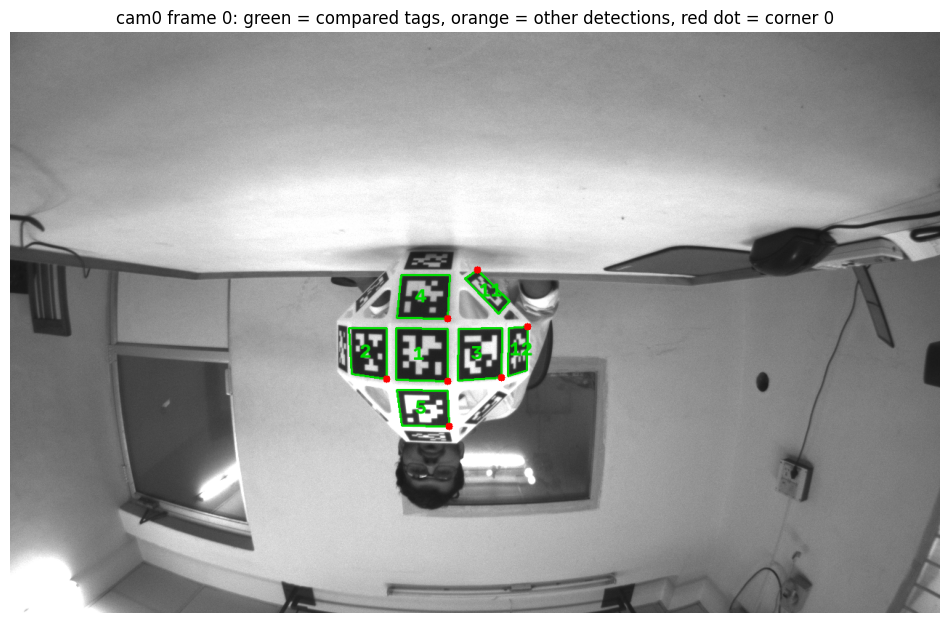

In [3]:
# Frame with detections
import msgpack
import msgpack_numpy as mpn

FRAME_PATH = RECORDING_DIR / f"{CAMERA}_frame.msgpack"
with FRAME_PATH.open("rb") as stream:
    unpacker = msgpack.Unpacker(stream, object_hook=mpn.decode)
    for _index, frame_image in zip(range(FRAME + 1), unpacker):
        pass

with DETECTION_CACHE.open("rb") as stream:
    frame_detections = pickle.load(stream)["cameras"][CAMERA]["detections"][FRAME]  # noqa: S301

canvas = (
    cv2.cvtColor(frame_image, cv2.COLOR_GRAY2BGR)
    if frame_image.ndim == 2
    else frame_image.copy()
)
compared_ids = {REFERENCE_ID, *RING_IDS}
for marker_id, corners in frame_detections.items():
    color = (0, 220, 0) if marker_id in compared_ids else (0, 200, 255)
    points = corners.astype(np.int32).reshape(-1, 1, 2)
    cv2.polylines(canvas, [points], True, color, 2)
    cv2.circle(canvas, tuple(int(v) for v in points[0, 0]), 5, (0, 0, 255), -1)  # corner 0
    centre = corners.mean(axis=0).astype(int)
    cv2.putText(canvas, str(marker_id), (centre[0] - 12, centre[1] + 8),
                cv2.FONT_HERSHEY_SIMPLEX, 0.9, color, 2, cv2.LINE_AA)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
plt.title(
    f"{CAMERA} frame {FRAME}: green = compared tags, orange = other detections, "
    "red dot = corner 0"
)
plt.axis("off")
plt.show()

In [4]:
# Measure
def estimate_marker_pose(corners, K, D):
    """Lowest-reprojection-error positive-depth IPPE pose of one square tag."""
    undistorted = cv2.fisheye.undistortPoints(
        np.asarray(corners, dtype=np.float64).reshape(-1, 1, 2), K, D, P=K
    ).reshape(4, 2)
    ok, rvecs, tvecs, _err = cv2.solvePnPGeneric(
        TAG_CORNERS, undistorted, K, None, flags=cv2.SOLVEPNP_IPPE_SQUARE
    )
    best = None
    for rvec, tvec in zip(rvecs, tvecs):
        tvec = np.asarray(tvec, dtype=np.float64).reshape(3)
        if tvec[2] <= 0:
            continue
        projected, _ = cv2.projectPoints(TAG_CORNERS, rvec, tvec, K, None)
        rmse = float(
            np.sqrt(np.mean(np.sum((projected.reshape(4, 2) - undistorted) ** 2, axis=1)))
        )
        if best is None or rmse < best[2]:
            best = (cv2.Rodrigues(rvec)[0], tvec, rmse)
    return best


calibration = toml.load(CALIBRATION_TOML)[CAMERA]
K = np.asarray(calibration["camera_matrix"], dtype=np.float64)
D = np.asarray(calibration["dist_coeffs"], dtype=np.float64).reshape(-1, 1)

with DETECTION_CACHE.open("rb") as stream:
    detections = pickle.load(stream)["cameras"][CAMERA]["detections"][FRAME]  # noqa: S301

poses = {
    marker_id: estimate_marker_pose(detections[marker_id], K, D)
    for marker_id in (REFERENCE_ID, *RING_IDS)
}
R_ref, t_ref, _ = poses[REFERENCE_ID]

In [5]:
# Tag poses in the camera frame
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_tbl_rows(50)
pl.Config.set_tbl_cols(30)
pl.Config.set_float_precision(3)

reference_euler = Rotation.from_matrix(R_ref).as_euler(EULER_ORDER, degrees=True)
print(f"{CAMERA} frame {FRAME}, camera coordinates")
print(f"tag 1 orientation in camera, xyz Euler (deg): {np.round(reference_euler, 3)}")
pl.DataFrame(
    {
        "tag": list(poses),
        "x_mm": [MM * poses[m][1][0] for m in poses],
        "y_mm": [MM * poses[m][1][1] for m in poses],
        "z_mm": [MM * poses[m][1][2] for m in poses],
        "reproj_px": [poses[m][2] for m in poses],
    }
)

cam0 frame 0, camera coordinates
tag 1 orientation in camera, xyz Euler (deg): [-178.904   -2.527 -179.569]


tag,x_mm,y_mm,z_mm,reproj_px
i64,f64,f64,f64,f64
1,-38.714,44.981,407.756,0.063
2,-97.171,46.179,433.226,1.167
3,18.277,45.576,421.509,0.089
4,-37.948,-11.496,424.528,0.008
5,-38.894,102.528,426.328,0.056
12,61.512,46.545,465.358,0.113
11,27.928,-18.469,464.450,0.373


In [6]:
# Compare against CAD
position_rows = []
orientation_rows = []
for marker_id in RING_IDS:
    R_meas, t_meas, _ = poses[marker_id]

    cad_offset = np.asarray(CAD_OFFSET_MM[marker_id]) / MM
    cad_vector_cam = R_ref @ cad_offset
    measured_vector_cam = t_meas - t_ref
    position_error = measured_vector_cam - cad_vector_cam
    position_rows.append(
        {
            "tag": marker_id,
            "meas_x": MM * measured_vector_cam[0],
            "meas_y": MM * measured_vector_cam[1],
            "meas_z": MM * measured_vector_cam[2],
            "cad_x": MM * cad_vector_cam[0],
            "cad_y": MM * cad_vector_cam[1],
            "cad_z": MM * cad_vector_cam[2],
            "err_x": MM * position_error[0],
            "err_y": MM * position_error[1],
            "err_z": MM * position_error[2],
            "err_norm": MM * float(np.linalg.norm(position_error)),
            "dist_err": MM
            * float(np.linalg.norm(measured_vector_cam) - np.linalg.norm(cad_vector_cam)),
        }
    )

    R_cad = Rotation.from_euler(EULER_ORDER, CAD_EULER_DEG[marker_id], degrees=True)
    R_pred = R_ref @ R_cad.as_matrix()
    measured_rel = Rotation.from_matrix(R_ref.T @ R_meas)
    error = Rotation.from_matrix(R_pred.T @ R_meas)
    meas_e = measured_rel.as_euler(EULER_ORDER, degrees=True)
    err_e = error.as_euler(EULER_ORDER, degrees=True)
    orientation_rows.append(
        {
            "tag": marker_id,
            "meas_rx": meas_e[0],
            "meas_ry": meas_e[1],
            "meas_rz": meas_e[2],
            "cad_rx": CAD_EULER_DEG[marker_id][0],
            "cad_ry": CAD_EULER_DEG[marker_id][1],
            "cad_rz": CAD_EULER_DEG[marker_id][2],
            "err_rx": err_e[0],
            "err_ry": err_e[1],
            "err_rz": err_e[2],
            "err_angle": float(np.degrees(error.magnitude())),
            "normal_err": float(
                np.degrees(
                    np.arccos(np.clip(R_meas[:, 2] @ R_pred[:, 2], -1.0, 1.0))
                )
            ),
        }
    )

position_table = pl.DataFrame(position_rows)
orientation_table = pl.DataFrame(orientation_rows)

In [7]:
# Position, tag 1 -> tag N in camera coordinates (mm)
position_table

tag,meas_x,meas_y,meas_z,cad_x,cad_y,cad_z,err_x,err_y,err_z,err_norm,dist_err
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2,-58.458,1.198,25.470,-55.887,-0.130,17.649,-2.571,1.328,7.822,8.340,5.169
3,56.991,0.594,13.753,57.220,0.721,12.656,-0.229,-0.127,1.097,1.127,0.022
4,0.766,-56.478,16.772,1.140,-56.303,16.234,-0.374,-0.175,0.538,0.678,0.313
5,-0.180,57.547,18.572,0.193,56.893,14.071,-0.373,0.654,4.501,4.564,1.863
12,100.226,1.564,57.602,100.447,1.839,52.221,-0.222,-0.275,5.381,5.393,2.384
11,66.642,-63.451,56.694,67.106,-62.548,54.942,-0.464,-0.902,1.753,2.025,1.150


In [8]:
# Orientation, tag N in tag 1's frame, xyz Euler (deg)
orientation_table

tag,meas_rx,meas_ry,meas_rz,cad_rx,cad_ry,cad_rz,err_rx,err_ry,err_rz,err_angle,normal_err
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2,-2.031,25.479,0.823,0.000,30.000,0.000,-2.444,-4.518,0.746,5.177,5.136
3,-0.213,-30.710,0.273,0.000,-30.000,0.000,-0.076,-0.710,0.235,0.752,0.714
4,29.356,-0.684,-0.088,30.000,0.000,0.000,-0.646,-0.636,0.266,0.944,0.907
5,-30.399,-1.043,0.570,-30.000,0.000,0.000,-0.394,-1.188,-0.028,1.252,1.252
12,-60.516,0.367,90.143,-60.000,0.000,90.000,-0.517,0.060,0.389,0.650,0.520
11,-67.438,0.356,135.473,-67.792,0.000,135.000,0.351,-0.303,0.508,0.689,0.464


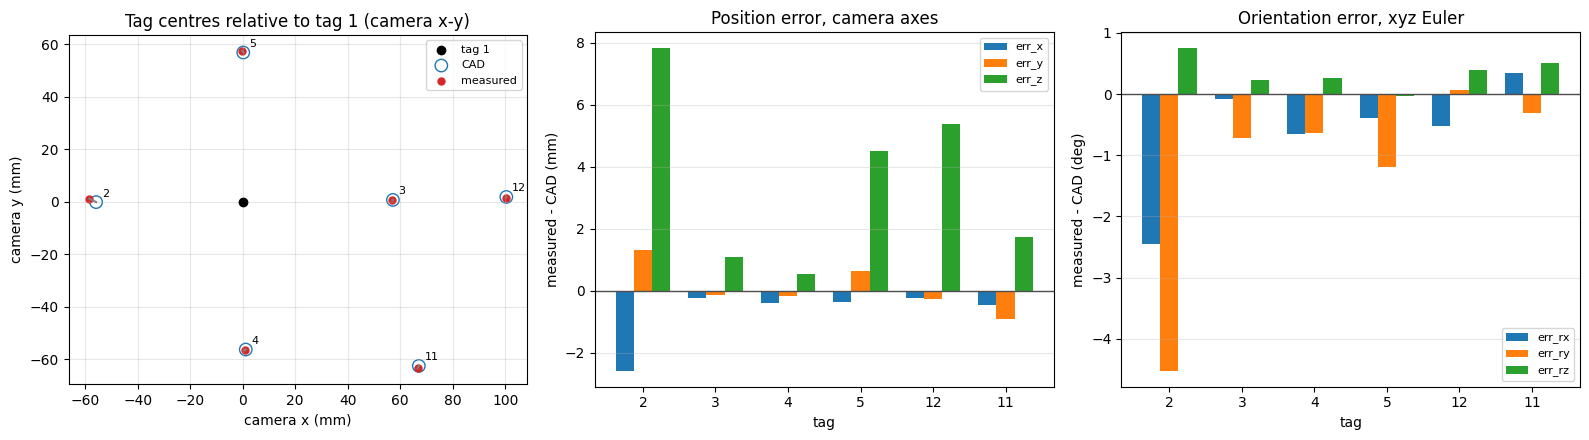

In [9]:
# Figure
tags = position_table["tag"].to_list()
figure, (axis_xy, axis_err, axis_rot) = plt.subplots(1, 3, figsize=(16, 4.5))

axis_xy.scatter([0], [0], color="k", label="tag 1", zorder=3)
for row in position_table.iter_rows(named=True):
    axis_xy.scatter(row["cad_x"], row["cad_y"], facecolors="none", edgecolors="tab:blue",
                    s=80, label="CAD" if row["tag"] == tags[0] else None)
    axis_xy.scatter(row["meas_x"], row["meas_y"], color="tab:red", s=25,
                    label="measured" if row["tag"] == tags[0] else None)
    axis_xy.plot([row["cad_x"], row["meas_x"]], [row["cad_y"], row["meas_y"]], color="0.5")
    axis_xy.annotate(str(row["tag"]), (row["cad_x"], row["cad_y"]), fontsize=8,
                     xytext=(4, 4), textcoords="offset points")
axis_xy.set_aspect("equal")
axis_xy.set_xlabel("camera x (mm)")
axis_xy.set_ylabel("camera y (mm)")
axis_xy.set_title("Tag centres relative to tag 1 (camera x-y)")
axis_xy.legend(fontsize=8)
axis_xy.grid(alpha=0.3)

width = 0.25
positions = np.arange(len(tags))
for offset, column in zip((-width, 0, width), ("err_x", "err_y", "err_z")):
    axis_err.bar(positions + offset, position_table[column].to_numpy(), width, label=column)
axis_err.set_xticks(positions, [str(t) for t in tags])
axis_err.set_xlabel("tag")
axis_err.set_ylabel("measured - CAD (mm)")
axis_err.set_title("Position error, camera axes")
axis_err.axhline(0, color="0.3", linewidth=1)
axis_err.legend(fontsize=8)
axis_err.grid(axis="y", alpha=0.3)

for offset, column in zip((-width, 0, width), ("err_rx", "err_ry", "err_rz")):
    axis_rot.bar(positions + offset, orientation_table[column].to_numpy(), width, label=column)
axis_rot.set_xticks(positions, [str(t) for t in tags])
axis_rot.set_xlabel("tag")
axis_rot.set_ylabel("measured - CAD (deg)")
axis_rot.set_title("Orientation error, xyz Euler")
axis_rot.axhline(0, color="0.3", linewidth=1)
axis_rot.legend(fontsize=8)
axis_rot.grid(axis="y", alpha=0.3)

figure.tight_layout()
plt.show()

## Rigid body vs CAD

The same tags, compared with the solved rigid body instead of the single frame. The rig is expressed in tag 1's frame (tag 1 at the origin with identity rotation), the same frame as the CAD constants, so nothing is aligned or fitted. The in-plane rolls of tags 11 and 12 are read from this rig, so their rotation error here is not independent; `normal_err` is.

In [10]:
# Rigid body vs CAD, tag 1 frame, no alignment
RIGIDBODY_TOML = RECORDING_DIR / "rigidbody_calibration.toml"
rigidbody_markers = toml.load(RIGIDBODY_TOML)["markers"]

rb_position_rows = []
rb_orientation_rows = []
for marker_id in RING_IDS:
    marker = rigidbody_markers[str(marker_id)]
    rb_t = np.asarray(marker["translation_marker_to_reference_m"], dtype=np.float64)
    rb_R = np.asarray(marker["rotation_marker_to_reference"], dtype=np.float64)

    cad_t = np.asarray(CAD_OFFSET_MM[marker_id]) / MM
    error_t = rb_t - cad_t
    rb_position_rows.append(
        {
            "tag": marker_id,
            "rb_x": MM * rb_t[0],
            "rb_y": MM * rb_t[1],
            "rb_z": MM * rb_t[2],
            "cad_x": MM * cad_t[0],
            "cad_y": MM * cad_t[1],
            "cad_z": MM * cad_t[2],
            "err_x": MM * error_t[0],
            "err_y": MM * error_t[1],
            "err_z": MM * error_t[2],
            "err_norm": MM * float(np.linalg.norm(error_t)),
            "dist_err": MM * float(np.linalg.norm(rb_t) - np.linalg.norm(cad_t)),
        }
    )

    R_cad = Rotation.from_euler(EULER_ORDER, CAD_EULER_DEG[marker_id], degrees=True)
    rb_rotation = Rotation.from_matrix(rb_R)
    error_r = R_cad.inv() * rb_rotation
    rb_e = rb_rotation.as_euler(EULER_ORDER, degrees=True)
    err_e = error_r.as_euler(EULER_ORDER, degrees=True)
    rb_orientation_rows.append(
        {
            "tag": marker_id,
            "rb_rx": rb_e[0],
            "rb_ry": rb_e[1],
            "rb_rz": rb_e[2],
            "cad_rx": CAD_EULER_DEG[marker_id][0],
            "cad_ry": CAD_EULER_DEG[marker_id][1],
            "cad_rz": CAD_EULER_DEG[marker_id][2],
            "err_rx": err_e[0],
            "err_ry": err_e[1],
            "err_rz": err_e[2],
            "err_angle": float(np.degrees(error_r.magnitude())),
            "normal_err": float(
                np.degrees(
                    np.arccos(np.clip(rb_R[:, 2] @ R_cad.as_matrix()[:, 2], -1.0, 1.0))
                )
            ),
        }
    )

rb_position_table = pl.DataFrame(rb_position_rows)
rb_orientation_table = pl.DataFrame(rb_orientation_rows)

In [11]:
# Rigid body position, tag 1 -> tag N in tag 1's frame (mm)
rb_position_table

tag,rb_x,rb_y,rb_z,cad_x,cad_y,cad_z,err_x,err_y,err_z,err_norm,dist_err
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2,56.688,0.045,-15.626,56.610,0.000,-15.170,0.078,0.045,-0.456,0.465,0.195
3,-56.805,-0.096,-15.476,-56.610,0.000,-15.170,-0.195,-0.096,-0.306,0.376,0.268
4,0.110,-57.006,-15.581,0.000,-56.610,-15.170,0.110,-0.396,-0.411,0.581,0.489
5,-0.215,56.688,-15.824,0.000,56.610,-15.170,-0.215,0.078,-0.654,0.692,0.248
12,-98.585,-0.350,-56.765,-98.058,0.000,-56.610,-0.527,-0.350,-0.155,0.651,0.534
11,-64.779,-65.081,-57.416,-64.146,-64.146,-56.610,-0.633,-0.935,-0.806,1.387,1.368


In [12]:
# Rigid body orientation, tag N in tag 1's frame, xyz Euler (deg)
rb_orientation_table

tag,rb_rx,rb_ry,rb_rz,cad_rx,cad_ry,cad_rz,err_rx,err_ry,err_rz,err_angle,normal_err
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2,-0.120,29.741,0.485,0.000,30.000,0.000,-0.362,-0.258,0.421,0.612,0.445
3,0.478,-29.713,-0.013,0.000,-30.000,0.000,0.471,0.287,-0.011,0.552,0.551
4,29.904,0.434,-0.028,30.000,0.000,0.000,-0.097,0.362,-0.241,0.445,0.375
5,-29.938,0.369,0.561,-30.000,0.000,0.000,0.061,0.039,0.671,0.674,0.072
12,-59.583,-0.052,90.288,-60.000,0.000,90.000,0.417,-0.276,0.099,0.510,0.500
11,-66.962,-0.039,134.898,-67.792,0.000,135.000,0.830,0.080,-0.075,0.837,0.833


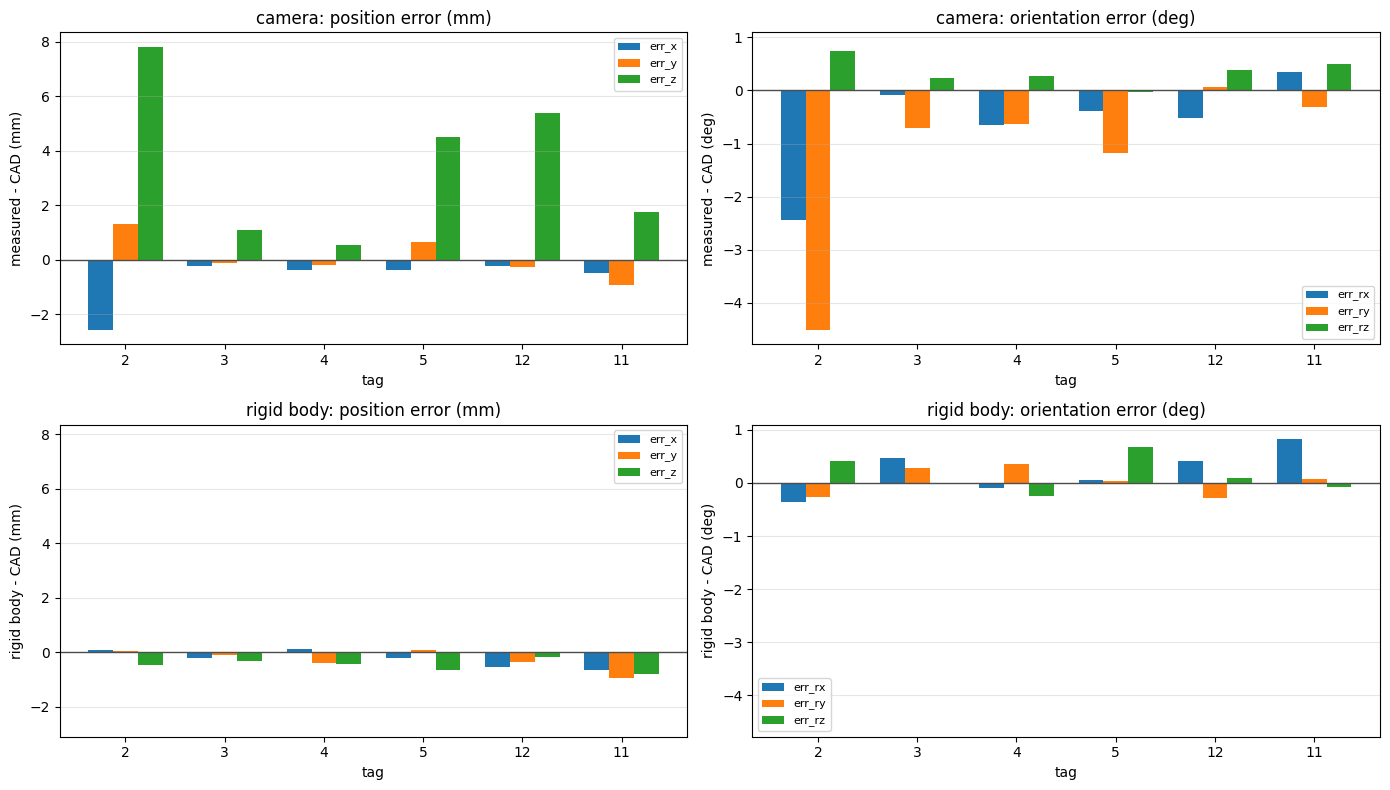

In [13]:
# Per-axis error vs CAD: camera frame (top) and rigid body (bottom)
tags = [str(t) for t in position_table["tag"]]
positions = np.arange(len(tags))
width = 0.25

panels = (
    (position_table, ("err_x", "err_y", "err_z"), "camera: position error (mm)"),
    (orientation_table, ("err_rx", "err_ry", "err_rz"), "camera: orientation error (deg)"),
    (rb_position_table, ("err_x", "err_y", "err_z"), "rigid body: position error (mm)"),
    (rb_orientation_table, ("err_rx", "err_ry", "err_rz"), "rigid body: orientation error (deg)"),
)
figure, axes = plt.subplots(2, 2, figsize=(14, 8), sharey="col")
for axis, (table, columns, title) in zip(axes.ravel(), panels):
    for offset, column in zip((-width, 0, width), columns):
        axis.bar(positions + offset, table[column].to_numpy(), width, label=column)
    axis.axhline(0, color="0.3", linewidth=1)
    axis.set_xticks(positions, tags)
    axis.set_xlabel("tag")
    axis.set_title(title)
    axis.legend(fontsize=8)
    axis.grid(axis="y", alpha=0.3)
axes[0, 0].set_ylabel("measured - CAD (mm)")
axes[1, 0].set_ylabel("rigid body - CAD (mm)")
axes[0, 1].set_ylabel("measured - CAD (deg)")
axes[1, 1].set_ylabel("rigid body - CAD (deg)")
figure.tight_layout()
plt.show()

In [14]:
# First frame vs rigid body, side by side
pl.DataFrame(
    {
        "tag": position_table["tag"],
        "pos_err_frame_mm": position_table["err_norm"],
        "pos_err_rb_mm": rb_position_table["err_norm"],
        "rot_err_frame_deg": orientation_table["err_angle"],
        "rot_err_rb_deg": rb_orientation_table["err_angle"],
    }
)

tag,pos_err_frame_mm,pos_err_rb_mm,rot_err_frame_deg,rot_err_rb_deg
i64,f64,f64,f64,f64
2,8.340,0.465,5.177,0.612
3,1.127,0.376,0.752,0.552
4,0.678,0.581,0.944,0.445
5,4.564,0.692,1.252,0.674
12,5.393,0.651,0.650,0.510
11,2.025,1.387,0.689,0.837
